# 04 - Breast cancer prediction: probabilities, ROC and thresholds

Binary diagnosis (malignant vs benign) from 30 cell-nucleus measurements. In medicine **accuracy is not enough**: we care about calibrated probabilities, the ROC / precision-recall trade-off and choosing a decision threshold.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import mlforge
from mlforge import visualization as viz
print("MLForge", mlforge.__version__)

MLForge 0.2.0


In [2]:
from sklearn.datasets import load_breast_cancer
d = load_breast_cancer(); X, y = d.data, d.target       # y=1 benign, 0 malignant
print(X.shape, "class balance:", np.bincount(y))
from mlforge.preprocessing import train_test_split, StandardScaler
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=0, stratify=y)
sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)

(569, 30) class balance: [212 357]


## Logistic regression: three solvers, one optimum
Gradient descent, Adam and Newton / IRLS minimise the same regularised loss, so they must reach the same weights.

GD      iterations=12000  final loss=0.074256  max|w - w_newton|=4.6e-08  test acc=0.9766
Adam    iterations= 1500  final loss=0.074256  max|w - w_newton|=1.1e-08  test acc=0.9766
Newton  iterations=   11  final loss=0.074256  max|w - w_newton|=0.0e+00  test acc=0.9766


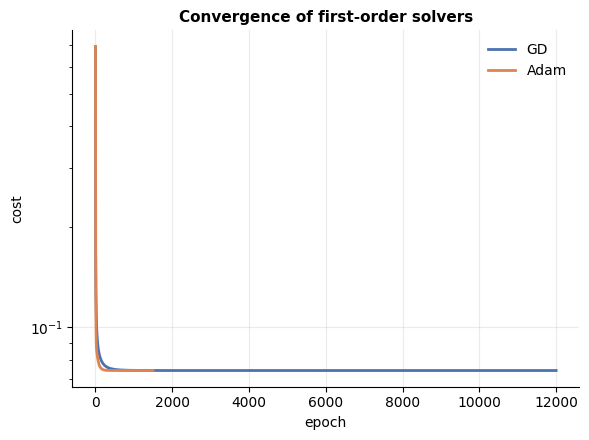

In [3]:
from mlforge.linear_model import LogisticRegression
fits = {"GD": LogisticRegression(solver="gd", C=1.0, learning_rate=0.5, n_iters=12000),
        "Adam": LogisticRegression(solver="gd", C=1.0, optimizer="adam", learning_rate=0.05, n_iters=1500),
        "Newton": LogisticRegression(solver="newton", C=1.0)}
for n, m in fits.items(): m.fit(Ztr, ytr)
ref = fits["Newton"].coef_
for n, m in fits.items(): print(f"{n:<7} iterations={len(m.cost_history_):>5}  final loss={m.cost_history_[-1]:.6f}  max|w - w_newton|={np.abs(m.coef_-ref).max():.1e}  test acc={m.score(Zte, yte):.4f}")
viz.plot_learning_curve({k: m.cost_history_ for k, m in fits.items() if k != "Newton"}, log_y=True, title="Convergence of first-order solvers");

## Several models, one ROC plot

Logistic       AUC=0.9980  AP=0.9988
Random forest  AUC=0.9974  AP=0.9985
Boosting       AUC=0.9985  AP=0.9991
SVM            AUC=0.9984  AP=0.9990
MLP            AUC=0.9963  AP=0.9977


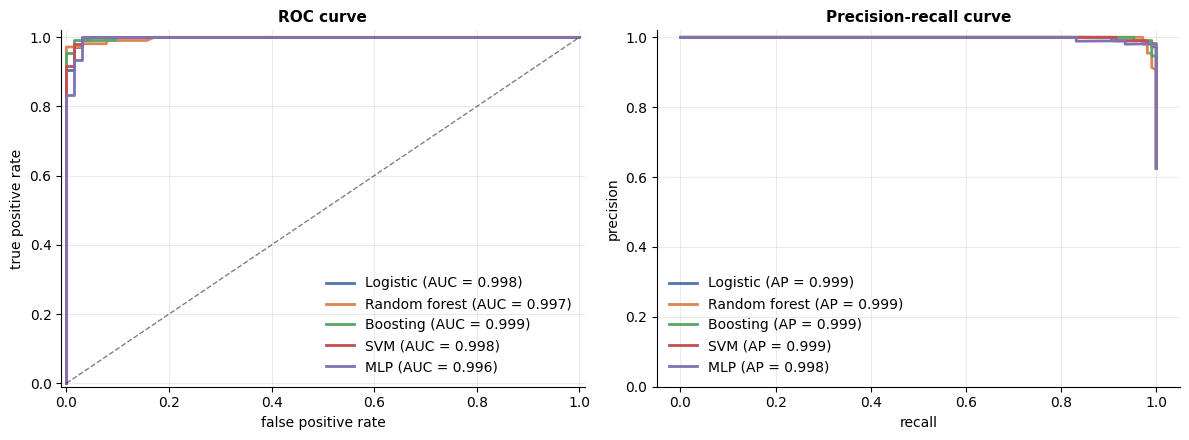

In [4]:
from mlforge.tree import RandomForestClassifier, GradientBoostingClassifier
from mlforge.svm import SVC
from mlforge.neural_network import MLPClassifier
from mlforge.metrics import roc_auc_score, average_precision_score
models = {"Logistic": fits["Newton"], "Random forest": RandomForestClassifier(100, random_state=0).fit(Ztr, ytr),
          "Boosting": GradientBoostingClassifier(100, random_state=0).fit(Ztr, ytr),
          "SVM": SVC(random_state=0).fit(Ztr, ytr),
          "MLP": MLPClassifier((32,), n_epochs=80, l2=1e-3, random_state=0).fit(Ztr, ytr)}
scores = {k: (m.predict_proba(Zte)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Zte)) for k, m in models.items()}
for k, s in scores.items(): print(f"{k:<14} AUC={roc_auc_score(yte, s):.4f}  AP={average_precision_score(yte, s):.4f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
viz.plot_roc_curve(yte, scores, ax=ax[0]); viz.plot_precision_recall_curve(yte, scores, ax=ax[1]); plt.tight_layout()

## Choosing a threshold
Missing a malignant case (false *negative*) is far worse than a false alarm. Move the threshold to trade precision for recall.

 threshold  precision   recall  missed cancers
       0.5      0.984    0.953               3
       0.3      0.955    0.984               1
       0.1      0.887    0.984               1
      0.05      0.831    1.000               0


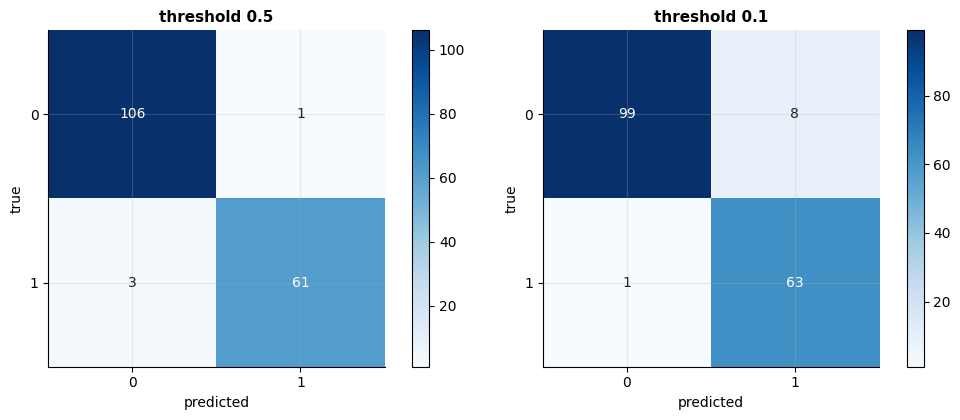

In [5]:
from mlforge.metrics import precision_score, recall_score, f1_score, confusion_matrix
p_malignant = 1 - models["Logistic"].predict_proba(Zte)[:, 1]
print(f"{'threshold':>10}{'precision':>11}{'recall':>9}{'missed cancers':>16}")
for t in [0.5, 0.3, 0.1, 0.05]:
    pred_malig = (p_malignant >= t).astype(int); true_malig = (yte == 0).astype(int)
    print(f"{t:>10}{precision_score(true_malig, pred_malig):>11.3f}{recall_score(true_malig, pred_malig):>9.3f}{int(((pred_malig == 0) & (true_malig == 1)).sum()):>16}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, t in zip(ax, [0.5, 0.1]):
    viz.plot_confusion_matrix((yte == 0).astype(int), (p_malignant >= t).astype(int), labels=[0, 1], ax=a, title=f"threshold {t}")
plt.tight_layout()

## What drives the prediction?

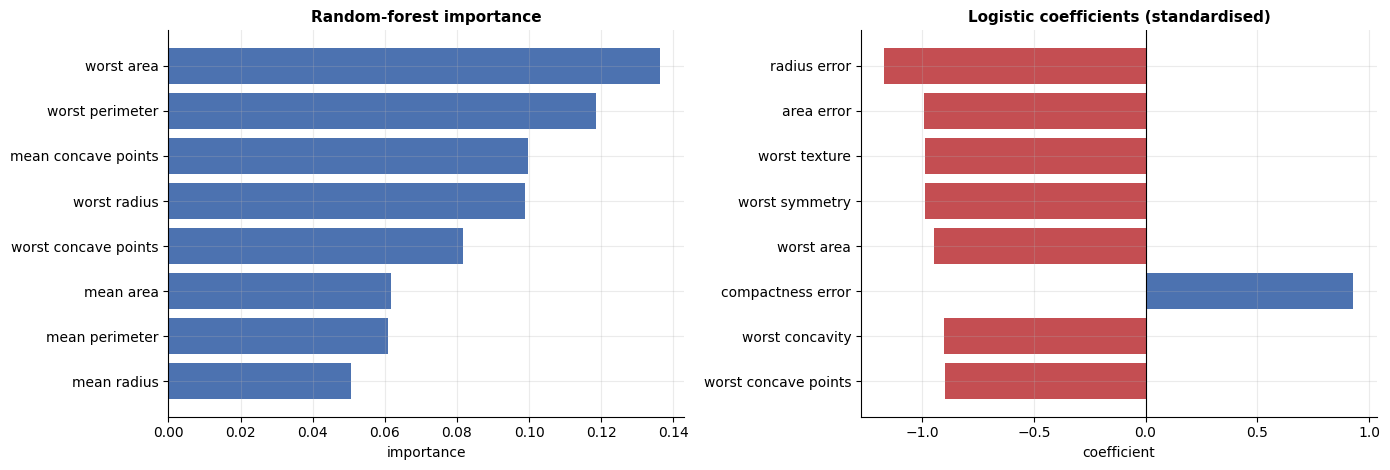

In [6]:
names = np.array(d.feature_names)
rf = models["Random forest"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
viz.plot_feature_importance(rf.feature_importances_, names, top_k=8, ax=ax[0], title="Random-forest importance")
order = np.argsort(np.abs(models["Logistic"].coef_))[::-1][:8][::-1]
viz.plot_coefficients(models["Logistic"].coef_[order], names[order], ax=ax[1], title="Logistic coefficients (standardised)"); plt.tight_layout()

## Is the model overfitting? Regularisation sweep with cross-validation

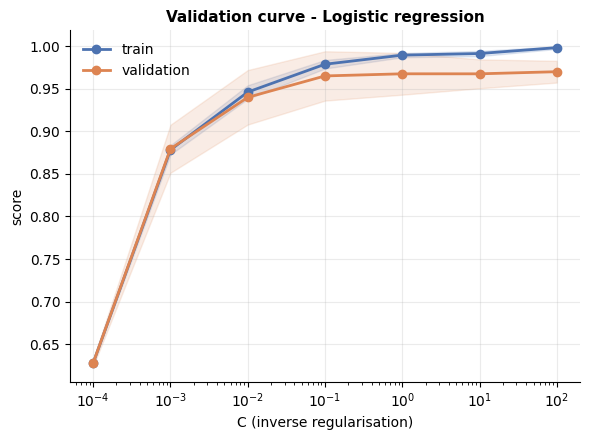

In [7]:
from mlforge.model_selection import validation_curve
Cs = np.logspace(-4, 2, 7)
tr, va = validation_curve(LogisticRegression(solver="newton"), Ztr, ytr, "C", Cs, cv=5)
viz.plot_model_selection_curve(Cs, tr, va, xlabel="C (inverse regularisation)", log_x=True, title="Validation curve - Logistic regression");